# Inicio del proyecto con UCI HAR 6 actividades

Características de sensores; investiguen el aporte de la información del giroscopio.

Este notebook carga los datos y explica su estructura. **No es una solución del proyecto.** Completen las secciones de investigación del final. Trabajen en Colab gratuito.

Fuente: https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones

## 1. Cargar los datos
Descompriman la entrega en su computador y abran este `.ipynb` en Colab. Ejecuten la siguiente celda y suban **ML_2026_11_10_UCI_HAR_6_actividades_DATOS.zip**, ubicado junto a este notebook. No suban el paquete general ni vuelvan a descargar la fuente original. La carga no necesita GPU.

In [1]:
from pathlib import Path
import io
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

archivo = Path('UCI_HAR_6_actividades.zip')
if not archivo.exists():
    from google.colab import files
    subidos = files.upload()
    if archivo.name not in subidos:
        raise ValueError("Sube el ZIP de DATOS que indica este notebook, con su nombre original.")

paquete = zipfile.ZipFile(archivo)
def leer_auxiliar(nombre):
    """Devuelve bytes de un archivo auxiliar incluido en este ZIP."""
    return io.BytesIO(paquete.read(nombre))

datos = np.load(leer_auxiliar('ML_2026_11_10_UCI_HAR_6_actividades_arrays.npz'), allow_pickle=False)
X, y = datos['X'], datos['y']
ids, split, nombres = datos['ids'], datos['split'], datos['names']
print('X:', X.shape, X.dtype, '| y:', y.shape)
print(dict(enumerate(nombres)))

X: (10299, 561) float32 | y: (10299,)
{0: np.str_('Caminar'), 1: np.str_('Subir escaleras'), 2: np.str_('Bajar escaleras'), 3: np.str_('Sentarse'), 4: np.str_('Estar de pie'), 5: np.str_('Acostarse')}


In [13]:
print("Eindeutige Splits:", np.unique(split, return_counts=True))
print("Anzahl eindeutiger Probanden (ids):", len(np.unique(ids)), "->", np.unique(ids))
print("Klassenverteilung in y:", np.unique(y, return_counts=True))
print("NaN-Werte in X:", np.isnan(X).sum())

Eindeutige Splits: (array(['test', 'train', 'val'], dtype='<U5'), array([2947, 5176, 2176]))
Anzahl eindeutiger Probanden (ids): 10299 -> [    0     1     2 ... 10296 10297 10298]
Klassenverteilung in y: (array([0, 1, 2, 3, 4, 5]), array([1722, 1544, 1406, 1777, 1906, 1944]))
NaN-Werte in X: 0


## 2. Respetar las particiones
Cada fila de `X`, `y`, `ids` y `split` corresponde a la misma observación. `y` es una etiqueta entera desde cero. Los identificadores y las etiquetas no son predictores. Usen `train` para aprender parámetros y transformaciones, `val` para elegir modelos y `test` para la evaluación final. La tabla de tamaños no evalúa ningún modelo.

In [3]:
# Identificar los ejemplos de cada partición
train = split == 'train'
val = split == 'val'
test = split == 'test'

# Separar las características
X_train = X[train]
X_val = X[val]
X_test = X[test]

# Separar las etiquetas
y_train = y[train]
y_val = y[val]
y_test = y[test]

# Mostrar el tamaño de cada conjunto
print("Ejemplos de entrenamiento:", len(y_train))
print("Ejemplos de validación:", len(y_val))
print("Ejemplos de test:", len(y_test))

Ejemplos de entrenamiento: 5176
Ejemplos de validación: 2176
Ejemplos de test: 2947


## 3. Escalar sin fuga de información
Las características ya están calculadas. El ejemplo ajusta un escalador **solo con entrenamiento** y transforma después validación y test. No vuelvan a ajustar el escalador sobre el conjunto completo. Para cada representación alternativa ajusten su propio escalador de entrenamiento. Los árboles no requieren este escalado.

In [4]:
from sklearn.preprocessing import StandardScaler
escalador = StandardScaler()
X_train_red = escalador.fit_transform(X_train).astype('float32')
X_val_red = escalador.transform(X_val).astype('float32')
X_test_red = escalador.transform(X_test).astype('float32')
print('Entrada preparada para MLP:', X_train_red.shape)

Entrada preparada para MLP: (5176, 561)


### Personas y grupos de variables
Las ventanas de una persona permanecen en una sola partición. Este control es esencial porque las ventanas no son observaciones independientes. Las 561 variables oficiales ya resumen señales; no estamos entrenando una red temporal. El ejemplo selecciona variables cuyo nombre contiene `Acc` y no `Gyro`; revisen la lista y el archivo de descripción para justificar qué consideran aceleración y cómo tratan variables mixtas.

In [5]:
# Identificador de la persona correspondiente a cada ejemplo
subject = datos['subject']

# Personas presentes en cada partición
personas_train = np.unique(subject[train])
personas_val = np.unique(subject[val])
personas_test = np.unique(subject[test])

print("Personas en entrenamiento:", personas_train)
print("Personas en validación:", personas_val)
print("Personas en test:", personas_test)

# Estas tres listas deben salir vacías
print("Personas compartidas entre train y val:",
      np.intersect1d(personas_train, personas_val))

print("Personas compartidas entre train y test:",
      np.intersect1d(personas_train, personas_test))

print("Personas compartidas entre val y test:",
      np.intersect1d(personas_val, personas_test))

Personas en entrenamiento: [ 1  3  5  7  8 11 14 16 17 19 21 22 25 28 29]
Personas en validación: [ 6 15 23 26 27 30]
Personas en test: [ 2  4  9 10 12 13 18 20 24]
Personas compartidas entre train y val: []
Personas compartidas entre train y test: []
Personas compartidas entre val y test: []


## 4. Desarrollar la investigación
Completen las siguientes secciones con texto, código y resultados. Consulten el enunciado y las rúbricas. No es necesario aplicar todas las ideas propuestas. Seleccionen una pregunta y una comparación que puedan justificar.

## Pregunta e hipótesis
¿Qué quieren averiguar y qué cambio observable esperan?

We want to investigate if the Gyro data improved the movement detection and by how much. The hypothesis is that including the Gyro data should improve the movement classification especially between standing and lying 

## Exploración y decisiones
¿Qué evidencia justifica su representación, preprocesamiento y métricas?

## Modelo de referencia y red neuronal
Implementen y justifiquen ambos modelos. Registren arquitectura, hiperparámetros, semillas, tiempos e historia de entrenamiento.

In [6]:
import sys
print(sys.version)

3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]


In [ ]:
!pip install tensorflow

In [8]:
import tensorflow as tf

In [56]:
import keras

from keras.models import Sequential # El modelo se construye agregando una capa después de otra

from keras.layers import Dense #totalmente conectadas: cada output se conecta con cada input

from keras.layers import Dropout #para regularización

from tensorflow.keras.callbacks import EarlyStopping


In [16]:
acc_ranges = [
    range(1, 121),    # tBodyAcc, tGravityAcc, tBodyAccJerk (1–120)
    range(201, 240),  # tBodyAccMag, tGravityAccMag, tBodyAccJerkMag (201–239)
    range(266, 424),  # fBodyAcc, fBodyAccJerk (266–423)
    range(503, 529),  # fBodyAccMag, fBodyBodyAccJerkMag (503–528)
    # Optional: reine Acc-Winkel am Ende (555, 556, 560, 561)
]

# In 0-basierte Python-Indizes umwandeln
acc_idx = [col - 1 for r in acc_ranges for col in r]

X_train_acc = X_train_red[:, acc_idx]
X_val_acc = X_val_red[:, acc_idx]
print("Shape von X_train_acc:", X_train_acc.shape)

Shape von X_train_acc: (5176, 343)


In [ ]:
print(y_train.shape)
print(np.unique(y_train))

In [70]:
model_acc = Sequential()
model_acc.add(Dense(128, activation='relu', input_shape=(343,)))
model_acc.add(Dropout(0.5)) 
model_acc.add(Dense(64, activation='relu'))
model_acc.add(Dropout(0.4)) 
model_acc.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_acc.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])
model_acc.summary()

Model: "sequential_24"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_69 (Dense)                │ (None, 128)            │        44,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_70 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_71 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,678 (205.77 KB)

 Trainable params: 52,678 (205.77 KB)

 Non-trainable params: 0 (0.00 B)

In [68]:
mynet_acc = model_acc.fit(X_train_acc, y_train, validation_data= (X_val_acc, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_acc.history['loss'])}")

Se detuvo en la época: 60


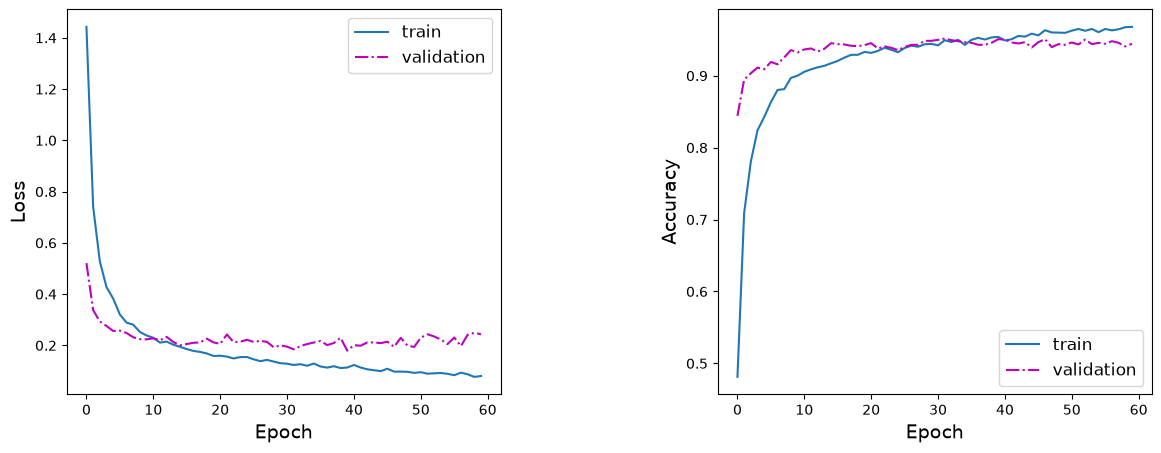

In [69]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))

plt.subplot(121)

plt.plot(mynet_acc.history['loss'], label = 'train') #mynet.history guarda la historia en cada época de la red
plt.plot(mynet_acc.history['val_loss'],'-.m', label = 'validation')
plt.ylabel('Loss', fontsize = 14)
plt.xlabel('Epoch', fontsize = 14)
plt.legend(loc='upper right', fontsize = 12)

plt.subplot(122)

plt.plot(mynet_acc.history['accuracy'], label = 'train')
plt.plot(mynet_acc.history['val_accuracy'], '-.m', label = 'validation')
plt.ylabel('Accuracy', fontsize = 14)
plt.xlabel('Epoch', fontsize = 14)
plt.legend(fontsize = 12)
plt.subplots_adjust(wspace=0.5)

#plt.show()

#plt.savefig('FirstNN.png', dpi= 300)

## Comparación controlada
Definan el factor que cambia y lo que mantienen fijo. Seleccionen con validación; repitan la comparación y comuniquen variabilidad.

## Evaluación final y errores
Evalúen condiciones predefinidas en test. Incluyan macro F1, matriz de confusión, pureza y completitud por clase, y ejemplos de errores.

## Conclusiones y fuentes
Respondan la pregunta con evidencia, limitaciones y alcance. Declaren fuentes, código reutilizado y apoyos utilizados.